# US Traffic Fatality Prediction — SHAP Interpretability Analysis
**DATA 495: Data Science Capstone**  
**Carl Stolpe | UMGC | May 2026**

This notebook applies SHAP (SHapley Additive exPlanations) to the Random Forest champion model to produce a theoretically rigorous, feature-level importance profile of the crash fatality classifier.

SHAP values are grounded in cooperative game theory and guarantee that the sum of each feature's contribution equals the difference between the model's prediction for a given record and the model's average prediction across the dataset (Lundberg & Lee, 2017).

**Sample:** 2,000 records drawn from the 2016 validation dataset using the TreeExplainer method.

## 1. Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings('ignore')

import os
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
SHAP_SAMPLE_SIZE = 2000
os.makedirs('../outputs/figures', exist_ok=True)

shap.initjs()
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Load Prepared Data and Retrain Champion Model

In [2]:
train_df = pd.read_csv('../data/fars_2015_prepared.csv')
val_df   = pd.read_csv('../data/fars_2016_prepared.csv')

# Same model features as 04_modeling.ipynb
FEATURES = [
    'AGE', 'HOUR', 'MONTH', 'DRUNK_DR',
    'SEX', 'LGT_COND', 'WEATHER', 'MAN_COLL', 'FUNC_SYS',
    'RURAL_URBAN', 'STATE', 'REST_USE', 'ALC_POSITIVE'
]
TARGET = 'INJ_SEV_BINARY'

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_val   = val_df[FEATURES]
y_val   = val_df[TARGET]

# Retrain Random Forest champion model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print('Champion model trained.')
print(f'Validation set: {X_val.shape[0]:,} records')

Champion model trained.
Validation set: 51,195 records


## 3. Draw SHAP Sample

SHAP TreeExplainer is computationally intensive on large datasets. A simple random sample of 2,000 records from the 2016 validation set is used; at this size its fatal rate closely matches the full validation set.

In [3]:
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_val), size=SHAP_SAMPLE_SIZE, replace=False)
X_shap = X_val.iloc[sample_idx].reset_index(drop=True)
y_shap = y_val.iloc[sample_idx].reset_index(drop=True)

print(f'SHAP sample size: {len(X_shap):,} records')
print(f'Fatal rate in sample: {y_shap.mean():.1%}')

SHAP sample size: 2,000 records
Fatal rate in sample: 46.9%


## 4. Compute SHAP Values

In [4]:
explainer   = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

# Older shap versions return a list [class 0, class 1];
# shap >= 0.45 returns one array shaped (records, features, classes).
if isinstance(shap_values, list):
    shap_fatal = shap_values[1]
else:
    shap_fatal = shap_values[..., 1]

assert shap_fatal.shape == X_shap.shape, f'Unexpected SHAP shape {shap_fatal.shape}'
print(f'SHAP values computed. Shape: {shap_fatal.shape}')

SHAP values computed. Shape: (2000, 13)


## 5. Mean Absolute SHAP Values — Feature Importance Table

In [5]:
mean_shap = pd.DataFrame({
    'Feature': FEATURES,
    'Mean |SHAP Value|': np.abs(shap_fatal).mean(axis=0)
}).sort_values('Mean |SHAP Value|', ascending=False).reset_index(drop=True)

mean_shap.index += 1
mean_shap.index.name = 'Rank'

print('SHAP Feature Importance Summary — Random Forest Champion Model')
print(f'(n={SHAP_SAMPLE_SIZE:,} validation records)')
print('-' * 45)
print(mean_shap.round(4).to_string())

SHAP Feature Importance Summary — Random Forest Champion Model
(n=2,000 validation records)
---------------------------------------------
           Feature  Mean |SHAP Value|
Rank                                 
1         REST_USE             0.1858
2              AGE             0.0484
3     ALC_POSITIVE             0.0461
4      RURAL_URBAN             0.0433
5         MAN_COLL             0.0420
6             HOUR             0.0208
7         DRUNK_DR             0.0126
8         LGT_COND             0.0097
9         FUNC_SYS             0.0083
10           STATE             0.0071
11             SEX             0.0060
12         WEATHER             0.0035
13           MONTH             0.0025


## 6. SHAP Summary Bar Chart

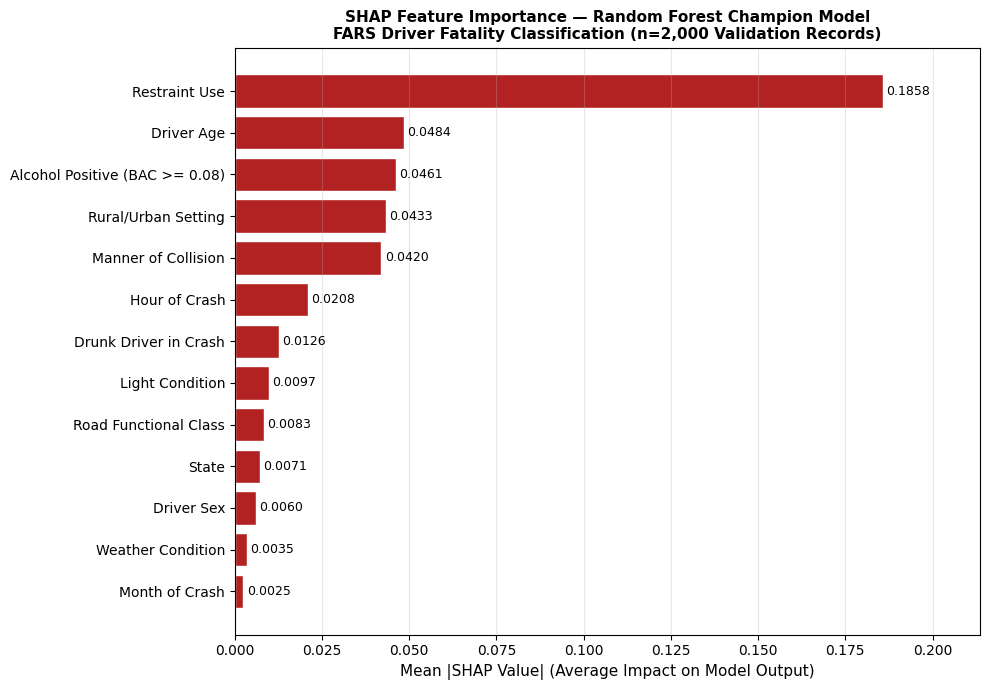

Figure saved.


In [6]:
# Friendly display names for features
feature_labels = {
    'REST_USE':    'Restraint Use',
    'ALC_POSITIVE':'Alcohol Positive (BAC >= 0.08)',
    'DRUNK_DR':    'Drunk Driver in Crash',
    'MAN_COLL':    'Manner of Collision',
    'AGE':         'Driver Age',
    'RURAL_URBAN': 'Rural/Urban Setting',
    'HOUR':        'Hour of Crash',
    'FUNC_SYS':    'Road Functional Class',
    'STATE':       'State',
    'LGT_COND':    'Light Condition',
    'WEATHER':     'Weather Condition',
    'MONTH':       'Month of Crash',
    'SEX':         'Driver Sex'
}

mean_shap_plot = mean_shap.copy()
mean_shap_plot['Feature'] = mean_shap_plot['Feature'].map(feature_labels)
mean_shap_plot = mean_shap_plot.sort_values('Mean |SHAP Value|', ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    mean_shap_plot['Feature'],
    mean_shap_plot['Mean |SHAP Value|'],
    color='firebrick',
    edgecolor='white'
)

for bar, val in zip(bars, mean_shap_plot['Mean |SHAP Value|']):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=9)

ax.set_xlabel('Mean |SHAP Value| (Average Impact on Model Output)', fontsize=11)
ax.set_title(
    f'SHAP Feature Importance — Random Forest Champion Model\n'
    f'FARS Driver Fatality Classification (n={SHAP_SAMPLE_SIZE:,} Validation Records)',
    fontsize=11, fontweight='bold'
)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, mean_shap_plot['Mean |SHAP Value|'].max() * 1.15)

plt.tight_layout()
plt.savefig('../outputs/figures/shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

## 7. SHAP Beeswarm Plot

The beeswarm plot shows both the magnitude and direction of each feature's impact on individual predictions — positive SHAP values push toward a fatal prediction, negative values push away.

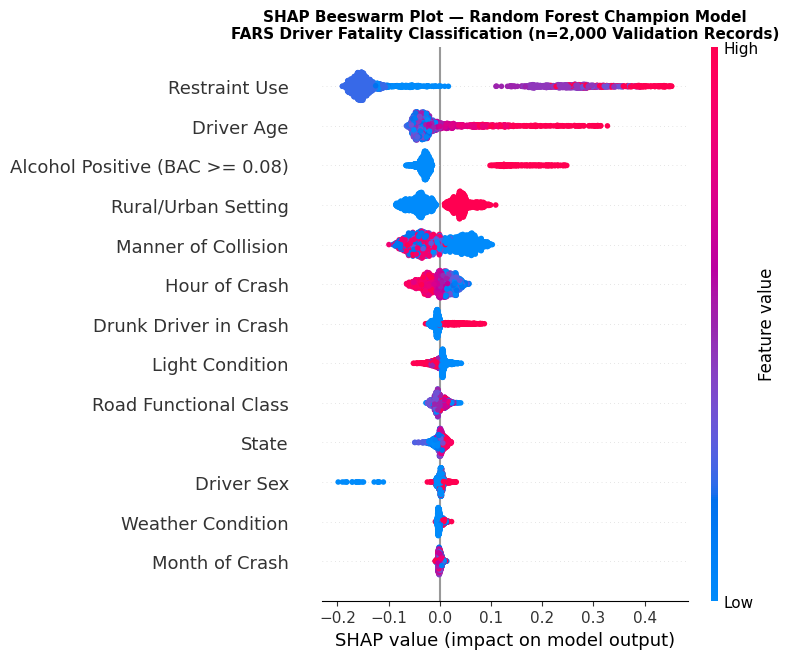

Figure saved.


In [7]:
fig, ax = plt.subplots(figsize=(10, 7))

shap.summary_plot(
    shap_fatal,
    X_shap,
    feature_names=[feature_labels.get(f, f) for f in FEATURES],
    plot_type='dot',
    show=False
)

plt.title(
    f'SHAP Beeswarm Plot — Random Forest Champion Model\n'
    f'FARS Driver Fatality Classification (n={SHAP_SAMPLE_SIZE:,} Validation Records)',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig('../outputs/figures/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')

## 8. Key Findings

Corrected run (November 2026):

| Rank | Feature | Mean \|SHAP Value\| | Interpretation |
|------|---------|-------------------|----------------|
| 1 | Restraint Use | 0.1858 | By far the strongest predictor. 27.7% of belted (lap + shoulder) drivers died vs. 78.4% of unrestrained drivers; unknown status sits in between (40.9%). Helmet codes also capture motorcyclists, who have very high fatality rates. |
| 2 | Driver Age | 0.0484 | Older drivers are much more likely to die: 68.0% of drivers over 75 and 54.8% of drivers 66–75 died, vs. 40–46% for younger age groups. |
| 3 | Alcohol Positive (BAC ≥ 0.08) | 0.0461 | 79.2% of drivers with a measured BAC ≥ 0.08 died vs. 41.2% of others. Probably overstated, because killed drivers are tested far more often than survivors (74.7% vs. 28.8%). |
| 4 | Rural/Urban Setting | 0.0433 | 53.1% of drivers in rural crashes died vs. 39.8% in urban crashes. |
| 5 | Manner of Collision | 0.0420 | Crash type (single-vehicle, head-on, angle) shapes the outcome. |
| 6 | Hour of Crash | 0.0208 | Captures traffic volume, lighting and impairment patterns by time of day. |
| 7 | Drunk Drivers in Crash | 0.0126 | Adds a little beyond the driver's own BAC. |

**Key insight:** restraint use has a mean absolute SHAP value nearly four times that of the next feature, so seatbelt use remains the single most important modifiable factor. Alcohol's importance is about half what the original (mis-coded) analysis reported.

**What changed from the original analysis:** Alcohol Positive dropped from 0.0988 to 0.0461 after fixing the BAC coding (the old check flagged 68% of drivers as positive; the correct figure is 13%). Rural/Urban rose from 0.0329 to 0.0433 after switching to the real rural/urban field. Total Crash Fatalities, which leaked the outcome, is no longer a model input.

**Reference:** Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30.*